### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [11]:
DPNM = data.copy()
DPNM = DPNM[DPNM['category']=='pulses and nuts']
DPNM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
16,1/15/2008,Rakhine,Maungdaw,Alel Than Kyaw,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,650.0,0.3652
19,1/15/2008,Rakhine,Maungdaw,Buthidaung,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,600.0,0.3371
22,1/15/2008,Rakhine,Maungdaw,Kyein Chung,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,500.0,0.2809
25,1/15/2008,Rakhine,Maungdaw,Maungdaw,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,570.0,0.3202
28,1/15/2008,Rakhine,Maungdaw,Myin Hlut,pulses and nuts,Chickpeas (local),local,NaN,KG,actual,Retail,MMK,450.0,0.2528


In [12]:
DPNM = DPNM[['date', 'price']]
DPNM['date'] = pd.to_datetime(DPNM['date'])
mask = (DPNM['date']>=obv_st_date) & (DPNM['date']<=obv_end_date)
DPNM = DPNM.loc[mask]
DPNM = DPNM.set_index('date')
DPNM.head()

,price
date,
2008-01-15,650.0
2008-01-15,600.0
2008-01-15,500.0
2008-01-15,570.0
2008-01-15,450.0


In [13]:
DPNM = DPNM.resample('MS').mean()
DPNM.head()

,price
date,
2008-01-01,623.095714
2008-02-01,800.952143
2008-03-01,835.064286
2008-04-01,597.618571
2008-05-01,531.092857


In [14]:
DPNM.shape

(169, 1)

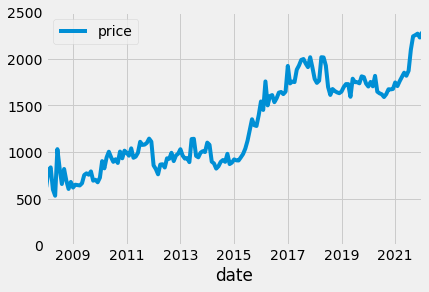

In [15]:
DPNM.plot(grid=True)
plt.show()

It has positive trend.

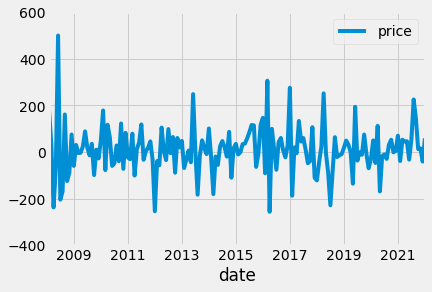

In [16]:
DPNM_diff1 = DPNM.diff(1).dropna()
DPNM_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [17]:
RW_DPNM= adfuller(DPNM_diff1)
RW_DPNM[1] # print P-value. If p-value<5%, reject null hypothesis

1.2498850271734752e-28

<span style="color:red">Are there any external factors that may influence this price?</span>

##### Plotting ACF and PACF

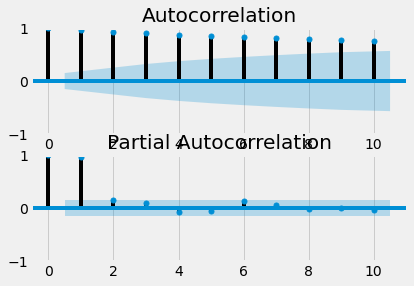

In [18]:
fig, axes=plt.subplots(2,1)
plot_acf(DPNM, lags=10, ax=axes[0])
plot_pacf(DPNM, lags=10, ax=axes[1])
plt.show()

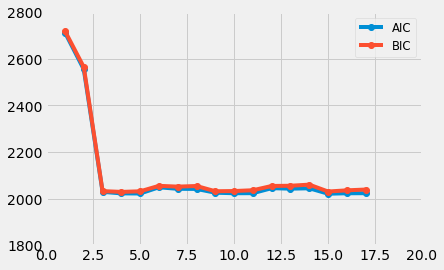

In [19]:
AIC, BIC = AIC_BIC_withOrderRange(DPNM, p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [20]:
AIC, BIC

(array([2922.06576042, 2712.01684102, 2554.40868031, 2029.14373087,
        2022.62360273, 2022.08378676, 2048.62033113, 2042.14505952,
        2041.64113067, 2025.41100243, 2023.19812503, 2023.52366634,
        2044.91104327, 2042.74364143, 2044.40873801, 2021.12493682,
        2023.10251536, 2023.38274764]),
 array([2925.19565913, 2718.27663845, 2563.79837646, 2032.26769484,
        2028.87153069, 2031.4556787 , 2054.88012856, 2051.53475566,
        2054.16072553, 2031.65893039, 2032.57001697, 2036.01952225,
        2054.30073941, 2055.26323629, 2060.05823158, 2030.49682876,
        2035.59837128, 2039.00256754]))

We will run again 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [21]:
mod_orders = [
    (0,1,0), 
    (0,1,1), 
    (0,1,2), 
    (1,1,0), 
    (1,1,1), 
    (1,1,2), 
    (2,1,0), 
    (2,1,1), 
    (2,1,2)
]

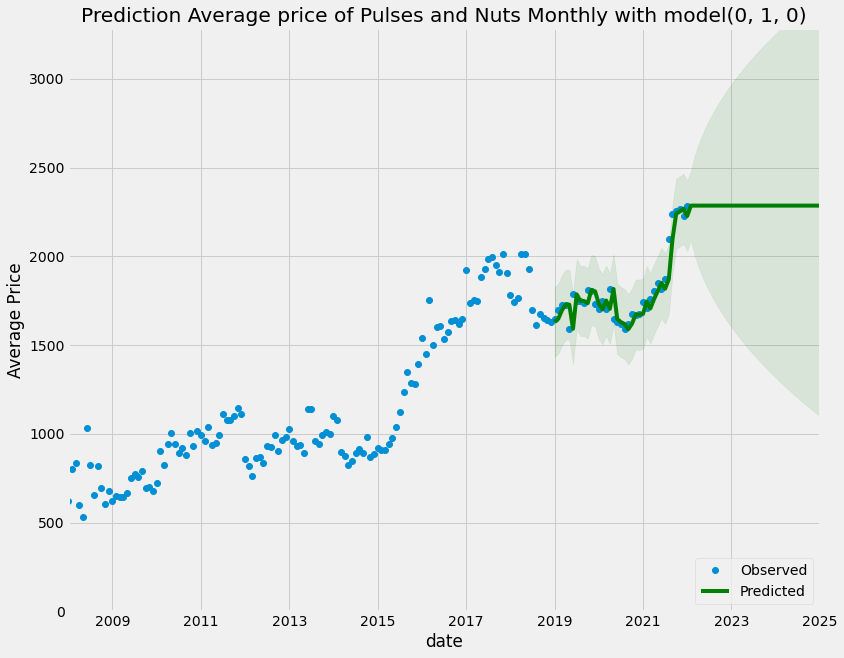

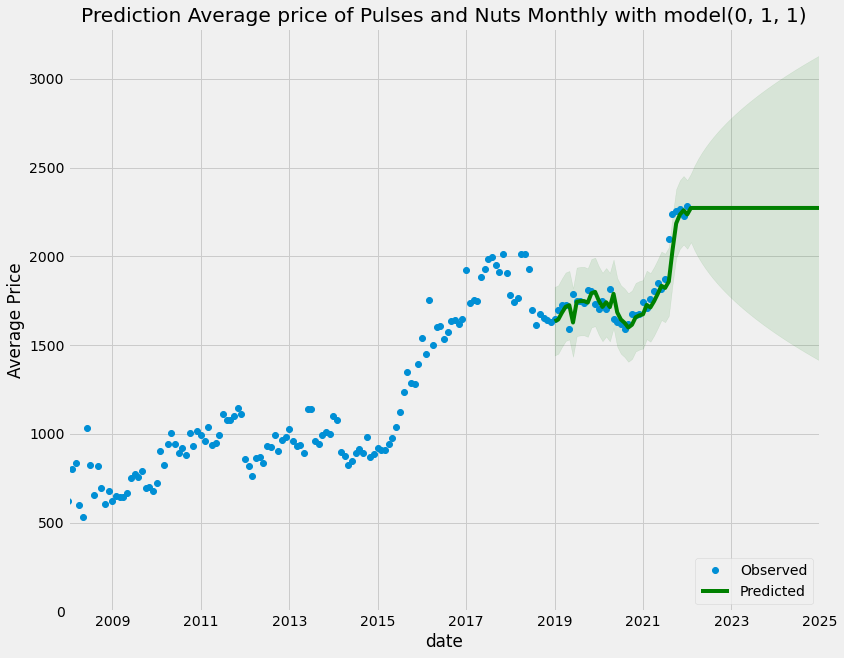

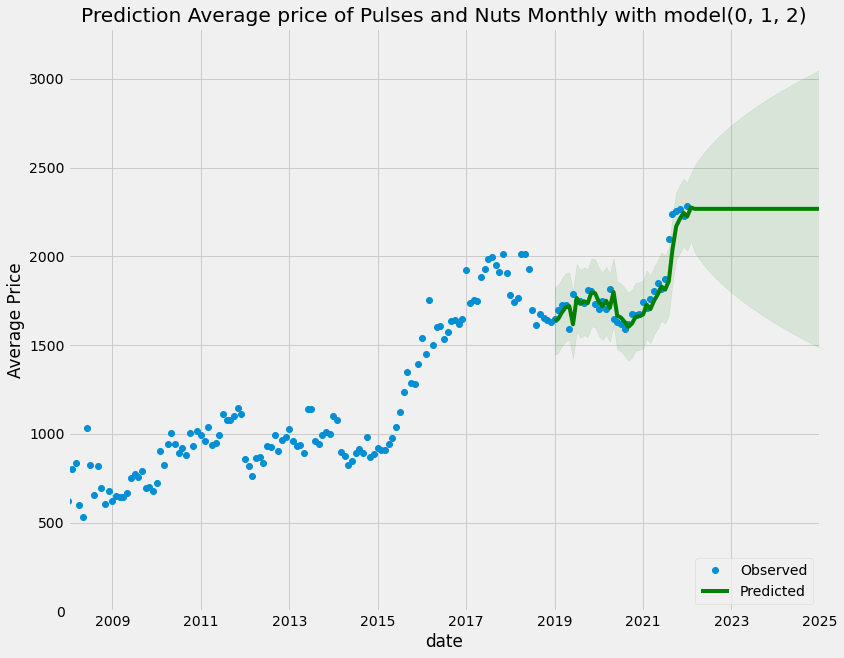

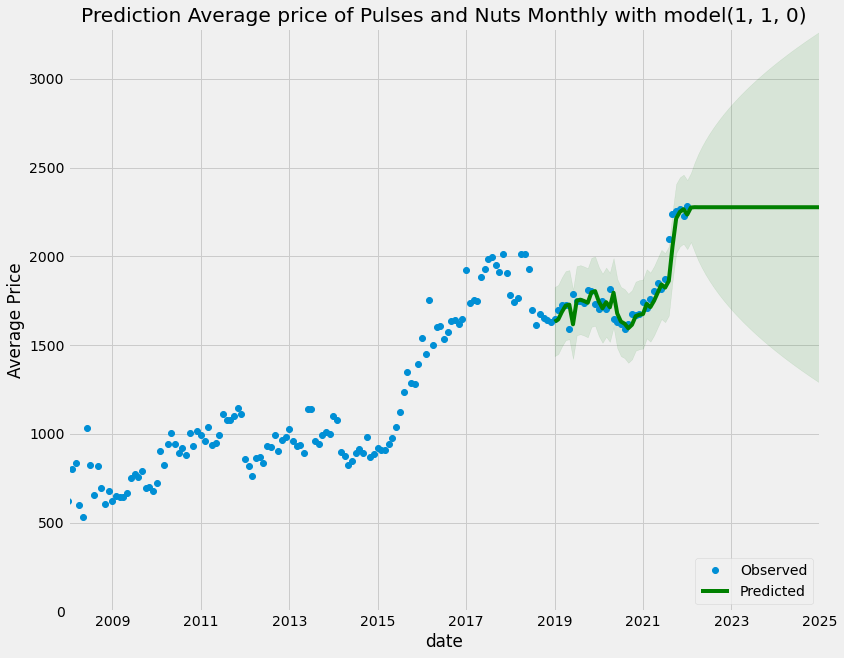

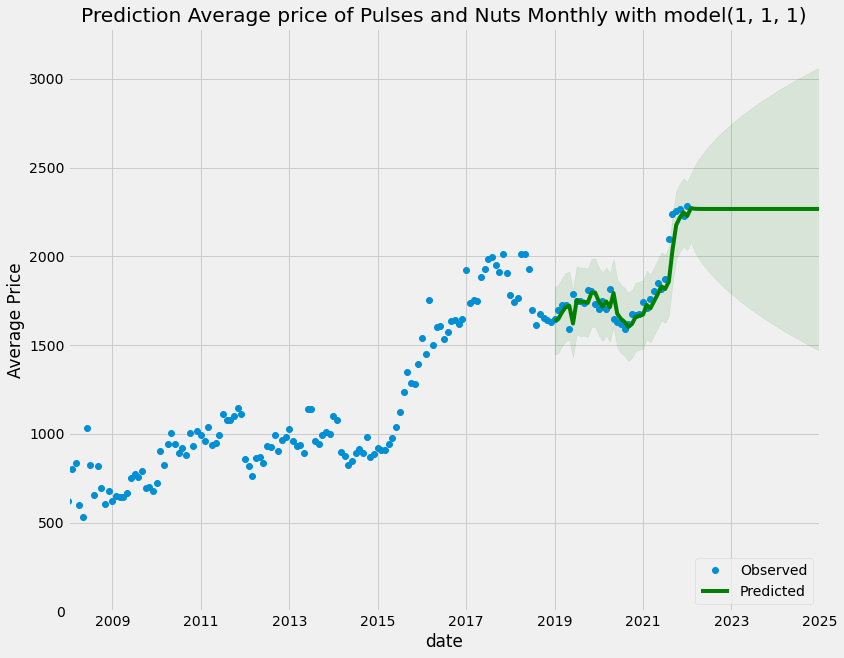

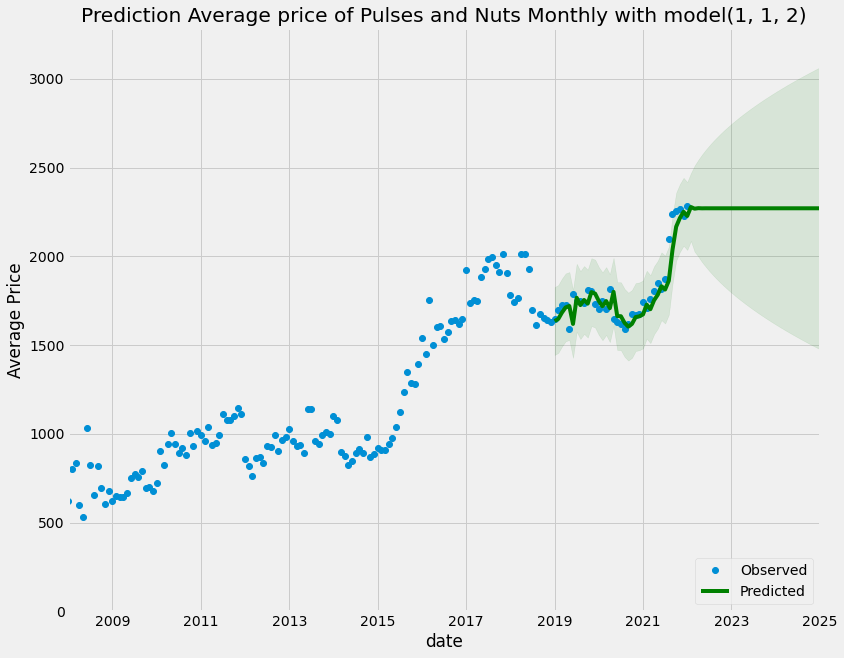

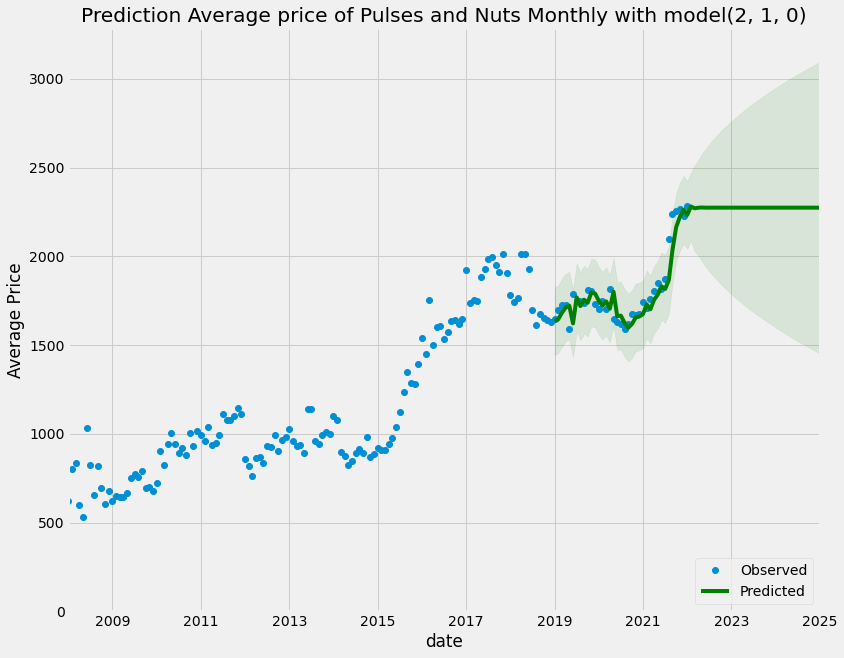

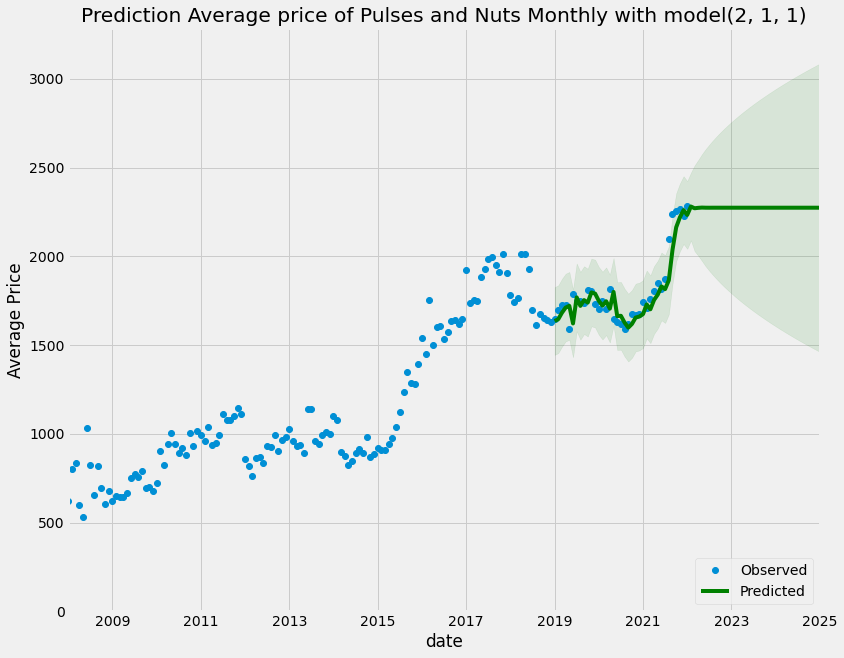

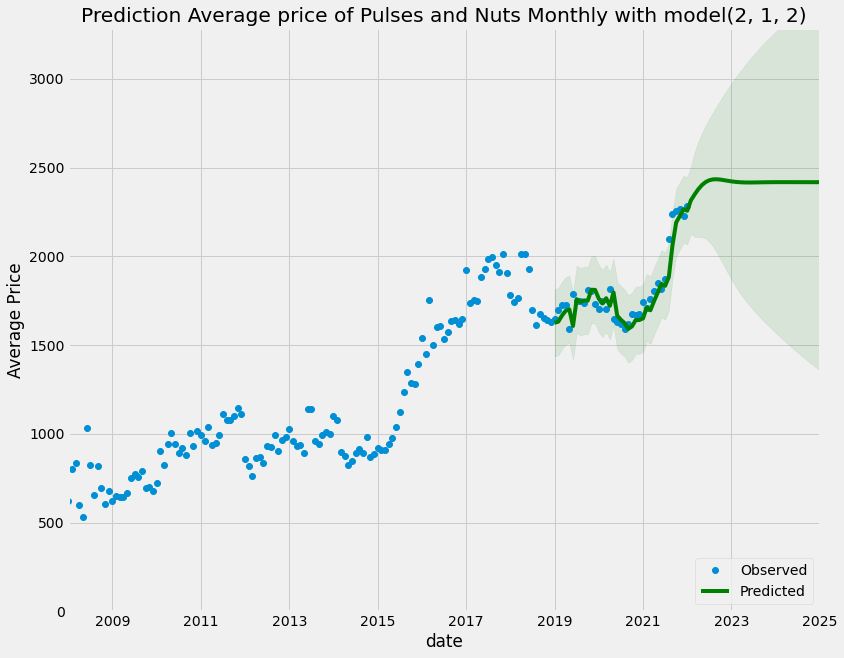

In [22]:
DPNM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DPNM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Pulses and Nuts Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DPNM_models.append(model)

Now we choose (0,1,0)

In [23]:
DPNM_model = DPNM_models[0]

In [24]:
DPNM_pred = DPNM_model.predict(pred_st_date, pred_end_date)
DPNM_pred

2019-01-01    1630.056364
2019-02-01    1647.423846
2019-03-01    1696.130769
2019-04-01    1727.665385
2019-05-01    1727.449286
                 ...     
2024-09-01    2285.335227
2024-10-01    2285.335227
2024-11-01    2285.335227
2024-12-01    2285.335227
2025-01-01    2285.335227
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64